# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Teninlanimi/flyrank-interenship-ml/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

My Models job is not to automatically refresh content. It's job is to produce a ranked decision-support queue for human review.
Logistic Regression had the strongest average Precision@K.
Mean Precision@20 = 0.83
Mean Precision@50 = 0.764
Mean Precision@100 = 0.742
Random Forest was second at P@20 = 0.76.
The honest client-level validation showed variation across folds, so these should be treated as observed ranking performance, not guaranteed future performance.


### Reason codes

- **STALE_VISIBLE** — Content is relatively old while still receiving meaningful visibility.
- **STALE_DECLINING** — Content shows both freshness risk and a declining performance signal.
- **DECLINING_VISIBLE** — Content shows a declining performance pattern while retaining measurable visibility.
- **POSITION_OPPORTUNITY** — Content has search visibility with a potential ranking opportunity.

Reason codes are intended to explain why a page was prioritized. They are descriptive signals, not causal explanations.

The ranked queue should be treated as a prioritization tool: higher-ranked pages should be reviewed first, but the score does not guarantee that refreshing the page will improve performance.


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

Who uses this?

Content strategists, SEO specialists, and content teams use the ranked queue to decide which existing pages deserve attention first.

What do they use it for?

They use it to prioritize content-refresh opportunities when they have limited time or resources. The model ranks pages and provides reason codes so reviewers can understand why a page was flagged.

Where does it stop being valid?

The model stops being valid as an automatic decision-maker. A high score does not mean a page should definitely be refreshed or that a refresh will improve performance. Human review is required because the model cannot fully account for factors such as business priorities, changes in search intent, seasonality, SERP changes, or important context not captured in the training data.

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

3) Human Review + No-Go List

What a person must check before acting

Before taking any content action, a human reviewer should:

Check the page’s current search intent and confirm it still matches the target query/topic.
Review recent impressions, clicks, CTR, and ranking position to understand the page’s current performance.
Check the reason code that caused the page to be prioritized.
Review the actual content for accuracy, quality, relevance, freshness, and completeness.
Consider business importance, such as whether the page supports an important product, service, or strategic topic.
Check for seasonality or recent changes in search demand that could make the model’s historical signal misleading.
Decide whether the appropriate action is actually to refresh, leave unchanged, merge, redirect, or retire the page.

No-go list: What should never be automated

The model should never automatically:

Publish or rewrite content.
Delete, redirect, or merge a page.
Change a page’s search intent or target topic.
Make claims about factual or business-sensitive information.
Override editorial, legal, compliance, or brand requirements.
Treat a high model score as proof that a refresh will increase traffic or rankings.
Make the final decision about whether a page should be changed.

Rule: The model can prioritize and explain, but a human must verify and decide.

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

The recommendations should be reviewed regularly because the relationship between content signals and refresh opportunities can change over time.

Monitoring signals:

Precision@K drops: The top-ranked pages are no longer frequently judged by humans to be genuine refresh opportunities.
Reason-code distribution changes: One reason code begins dominating the queue unexpectedly, or previously useful reason codes become rare.
Feature drift: Important inputs such as impressions, CTR, search volume, or content age shift substantially from the data used during training.
Performance changes: The model's ranking quality becomes noticeably weaker on newer data.
Human-review disagreement increases: Reviewers increasingly reject high-ranked recommendations.
Search behavior changes: Major changes in search intent, SERPs, algorithms, or seasonality make historical patterns less reliable.

Retrain / review triggers:

Retraining should be considered when there is sustained performance degradation, significant feature drift, or a clear increase in human disagreement with the recommendations. A major change in the underlying data or content environment should also trigger a model review.

The model should not be retrained simply because time has passed. Retraining should be based on evidence that the existing recommendations are no longer reliable.

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

In [87]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


def find_repo_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw" / "content_refresh_anonymized.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find the repo root containing data/raw/content_refresh_anonymized.csv")

repo_root = find_repo_root()
data_path = repo_root / "data" / "raw" / "content_refresh_anonymized.csv"

df = pd.read_csv(data_path)
print(df.shape)
df.head()

(30000, 44)


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


In [88]:
%whos

Variable                     Type                      Data/Info
----------------------------------------------------------------
ConfusionMatrixDisplay       type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier       ABCMeta                   <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GroupShuffleSplit            ABCMeta                   <class 'sklearn.model_sel<...>split.GroupShuffleSplit'>
LogisticRegression           type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
MODEL_CATEGORICAL_FEATURES   list                      n=8
MODEL_NUMERIC_FEATURES       list                      n=18
OUTPUT_DIR                   WindowsPath               ..\outputs
Path                         type                      <class 'pathlib._local.Path'>
RandomForestClassifier       ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer                type            

In [89]:
#Missing Values
numeric_columns = [
    "word_count",
    "char_count",
    "avg_position",
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "ai_sessions_90d",
    "days_since_last_update"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())
    # Feature Engineering
# Repository log features

df["log_impressions_90d"] = np.log1p(df["impressions_90d"])
df["log_clicks_90d"] = np.log1p(df["clicks_90d"])
df["log_sessions_90d"] = np.log1p(df["sessions_90d"])
df["log_ai_sessions_90d"] = np.log1p(df["ai_sessions_90d"])

# Repository target

df["is_declining_label"] = (
    df["trend_direction"]
      .str.lower()
      .eq("down")
      .astype(int)
)

In [90]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["is_declining_label"].value_counts())

print("\nClient count:")
print(df["client_id"].nunique())

Shape: (30000, 49)

Columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct', 'log_impressions_90d', 'log_clicks_90d', 'log_sessions_90d', 'log_ai_sessions_90d', 'is_declining_label']

Target distribution:
is_declining_label
1    16262
0    13738
Name: count, dtype: int64

Clie

In [91]:
# Check that all required features exist
required_features = (
    MODEL_NUMERIC_FEATURES
    + MODEL_CATEGORICAL_FEATURES
    + [TARGET, "content_id", "client_id"]
)

missing = [c for c in required_features if c not in df.columns]

print("Missing features:", missing)

Missing features: []


In [92]:
# Find all DataFrames currently available in the notebook

dataframes = []

for name, obj in list(globals().items()):
    if hasattr(obj, "shape") and hasattr(obj, "columns"):
        dataframes.append((name, obj))

for name, obj in dataframes:
    print(f"\n{name}")
    print("Shape:", obj.shape)
    print("Columns:", obj.columns.tolist())


_
Shape: (5, 44)
Columns: ['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']

__
Shape: (15, 2)
Columns: ['Feature', 'Importance']

___
Shape: (4, 4)
Columns: ['Method', 'Precision@20', 'Precision@50', 'Precision@100']

df
Shape: (30000, 49)
Columns: ['content_id', 'client_id', 

In [93]:
# Show non-DataFrame variables that may be related to the model

for name, obj in list(globals().items()):
    if not hasattr(obj, "columns"):
        name_lower = name.lower()
        if any(word in name_lower for word in [
            "model", "pred", "prob", "score", "logistic",
            "random", "forest", "tree", "test", "valid"
        ]):
            print(name, "->", type(obj).__name__)

train_test_split -> function
accuracy_score -> function
precision_score -> function
recall_score -> function
f1_score -> function
roc_auc_score -> function
average_precision_score -> function
LogisticRegression -> type
DecisionTreeClassifier -> ABCMeta
RandomForestClassifier -> ABCMeta
MODEL_NUMERIC_FEATURES -> list
MODEL_CATEGORICAL_FEATURES -> list
test_idx -> ndarray
y_test -> Series
baseline_scores -> Series
lr_pred -> ndarray
lr_prob -> ndarray
dt_pred -> ndarray
dt_prob -> ndarray
rf_pred -> ndarray
rf_prob -> ndarray
best_model_name -> str
best_model_scores -> ndarray
best_model -> LogisticRegression


In [94]:
print("Numeric features:")
print(MODEL_NUMERIC_FEATURES)

print("\nCategorical features:")
print(MODEL_CATEGORICAL_FEATURES)

Numeric features:
['search_volume', 'competition', 'cpc', 'word_count', 'char_count', 'log_impressions_90d', 'log_clicks_90d', 'log_sessions_90d', 'log_ai_sessions_90d', 'days_with_impressions', 'days_with_sessions', 'content_age_days', 'days_since_last_update', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct']

Categorical features:
['competition_level', 'content_type', 'main_intent', 'age_tier', 'freshness_tier', 'word_count_tier', 'impression_tier', 'position_tier']


In [95]:

# Repository Feature Lists

MODEL_NUMERIC_FEATURES = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "char_count",
    "log_impressions_90d",
    "log_clicks_90d",
    "log_sessions_90d",
    "log_ai_sessions_90d",
    "days_with_impressions",
    "days_with_sessions",
    "content_age_days",
    "days_since_last_update",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "ai_traffic_pct",
]

MODEL_CATEGORICAL_FEATURES = [
    "competition_level",
    "content_type",
    "main_intent",
    "age_tier",
    "freshness_tier",
    "word_count_tier",
    "impression_tier",
    "position_tier",
]

TARGET = "is_declining_label"

print("Numeric Features:", len(MODEL_NUMERIC_FEATURES))
print("Categorical Features:", len(MODEL_CATEGORICAL_FEATURES))

Numeric Features: 18
Categorical Features: 8


In [96]:

# Repository Baseline Refresh Score

def percentile_rank(series):
    """Convert values to percentile ranks between 0 and 1."""
    return series.rank(method="average", pct=True)

def normalize(series):
    """Normalize values between 0 and 1."""
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(np.zeros(len(series)), index=series.index)

    return (series - minimum) / (maximum - minimum)


# Visibility score
df["visibility_score"] = percentile_rank(
    np.log1p(df["impressions_90d"])
)

# Freshness score
df["freshness_risk_score"] = percentile_rank(
    df["days_since_last_update"]
)

# Position opportunity
df["position_opportunity_score"] = (
    (1 - normalize(df["avg_position"].clip(lower=1, upper=50)))
    * df["visibility_score"]
    * (df["avg_position"] > 0).astype(int)
)

# Content depth opportunity
df["depth_gap_score"] = (
    1 - percentile_rank(df["word_count"])
) * df["visibility_score"]

# Final baseline score
df["baseline_refresh_score"] = (
      0.40 * df["visibility_score"]
    + 0.30 * df["freshness_risk_score"]
    + 0.25 * df["position_opportunity_score"]
    + 0.05 * df["depth_gap_score"]
).clip(0, 1)

df["baseline_refresh_score"].describe()

count    30000.000000
mean         0.448383
std          0.214156
min          0.007958
25%          0.282475
50%          0.443107
75%          0.622012
max          0.938382
Name: baseline_refresh_score, dtype: float64

In [97]:

# One-Hot Encode Repository Features

model_df = df[
    MODEL_NUMERIC_FEATURES +
    MODEL_CATEGORICAL_FEATURES +
    [
        "client_id",
        TARGET,
        "baseline_refresh_score"
    ]
].copy()

model_df = pd.get_dummies(
    model_df,
    columns=MODEL_CATEGORICAL_FEATURES,
    drop_first=True
)

print(model_df.shape)
model_df.head()

(30000, 44)


,search_volume,competition,cpc,word_count,char_count,log_impressions_90d,log_clicks_90d,log_sessions_90d,log_ai_sessions_90d,days_with_impressions,...,word_count_tier_2000-3500,word_count_tier_3500+,word_count_tier_<1000,impression_tier_good,impression_tier_low,impression_tier_moderate,position_tier_page_1,position_tier_page_3_5,position_tier_striking,position_tier_top_3
0,10.0,0.67,2.05,3221.0,20457.0,8.243808,3.401197,2.890372,0.0,88,...,True,False,False,True,False,False,False,False,True,False
1,90.0,0.01,0.05,2481.0,15562.0,9.636980,2.079442,2.302585,0.0,88,...,True,False,False,True,False,False,False,True,False,False
2,0.0,0.00,0.00,3515.0,23643.0,9.440023,2.484907,2.484907,0.0,88,...,False,True,False,True,False,False,False,True,False,False
3,10.0,0.00,0.00,2877.0,19116.0,9.371779,4.077537,4.369448,0.0,88,...,False,False,False,True,False,False,True,False,False,False
4,0.0,0.00,0.00,2803.0,17469.0,9.859588,3.218876,4.983607,0.0,88,...,True,False,False,True,False,False,False,True,False,False


In [98]:

# Client Holdout Split


from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        model_df,
        groups=model_df["client_id"]
    )
)

train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

print("Train size:", train_df.shape)
print("Test size:", test_df.shape)

Train size: (23837, 44)
Test size: (6163, 44)


In [99]:

# Create X and y

X_train = train_df.drop(
    columns=[
        TARGET,
        "client_id",
        "baseline_refresh_score"
    ]
)

y_train = train_df[TARGET]

X_test = test_df.drop(
    columns=[
        TARGET,
        "client_id",
        "baseline_refresh_score"
    ]
)

y_test = test_df[TARGET]

baseline_scores = test_df["baseline_refresh_score"]

print(X_train.shape)
print(X_test.shape)

(23837, 41)
(6163, 41)


In [100]:
# Check missing values

missing = X_train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

search_volume    2319
competition      2319
cpc              2319
scroll_rate        15
dtype: int64


In [101]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

0
0


In [102]:

# Train Models
from sklearn.preprocessing import StandardScaler

# Logistic Regression
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(X_train, y_train)

# Decision Tree
dt = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

dt.fit(X_train, y_train)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=12,
    min_samples_leaf=3,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("Models trained successfully.")

c:\Users\Teninlanimi\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Models trained successfully.


In [103]:

# Generate Predictions


# Logistic Regression
lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:,1]

# Decision Tree
dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:,1]

# Random Forest
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]

print("Predictions complete.")

Predictions complete.


In [104]:
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Logistic Regression scores:", len(lr_prob))
print("Decision Tree scores:", len(dt_prob))
print("Random Forest scores:", len(rf_prob))
print("Baseline scores:", len(baseline_scores))

X_test: (6163, 41)
y_test: (6163,)
Logistic Regression scores: 6163
Decision Tree scores: 6163
Random Forest scores: 6163
Baseline scores: 6163


In [105]:
best_model_name = "Logistic Regression"
best_model_scores = lr_prob

print("Selected model:", best_model_name)
print("Number of scores:", len(best_model_scores))

Selected model: Logistic Regression
Number of scores: 6163


In [106]:
print("X_test index:", X_test.index[:10].tolist())
print("test_df index:", test_df.index[:10].tolist())
print("df index:", df.index[:10].tolist())
print("Does df have content_id?", "content_id" in df.columns)
print("Does test_df have content_id?", "content_id" in test_df.columns)

X_test index: [0, 1, 5, 13, 19, 20, 22, 23, 25, 26]
test_df index: [0, 1, 5, 13, 19, 20, 22, 23, 25, 26]
df index: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Does df have content_id? True
Does test_df have content_id? False


In [107]:
test_content = df.loc[
    test_df.index,
    ["content_id", "client_id"]
].copy()

print(test_content.shape)
print(test_content.head())

(6163, 2)
              content_id          client_id
0   content_304f48230142  client_f369cb89fc
1   content_a1fb4e703a9e  client_4e07408562
5   content_d4084a4bc775  client_f369cb89fc
13  content_a5a2fbc76336  client_8527a891e2
19  content_af865035b328  client_f369cb89fc


In [108]:
ranked_results = test_content.copy()

ranked_results["is_declining_label"] = y_test.values
ranked_results["baseline_refresh_score"] = baseline_scores.values
ranked_results["model_score"] = best_model_scores

print(ranked_results.shape)
ranked_results.head()

(6163, 5)


,content_id,client_id,is_declining_label,baseline_refresh_score,model_score
0,content_304f48230142,client_f369cb89fc,1,0.565521,0.693690
1,content_a1fb4e703a9e,client_4e07408562,1,0.741151,0.577653
5,content_d4084a4bc775,client_f369cb89fc,1,0.578673,0.807698
13,content_a5a2fbc76336,client_8527a891e2,0,0.397443,0.656871
19,content_af865035b328,client_f369cb89fc,1,0.275452,0.605116


In [109]:
print("Missing model scores:", ranked_results["model_score"].isna().sum())
print("Missing baseline scores:", ranked_results["baseline_refresh_score"].isna().sum())
print("Missing labels:", ranked_results["is_declining_label"].isna().sum())

Missing model scores: 0
Missing baseline scores: 0
Missing labels: 0


In [110]:
ranked_results = ranked_results.sort_values(
    "model_score",
    ascending=False
).reset_index(drop=True)

ranked_results["rank"] = range(
    1,
    len(ranked_results) + 1
)

ranked_results = ranked_results[
    [
        "rank",
        "content_id",
        "client_id",
        "is_declining_label",
        "baseline_refresh_score",
        "model_score"
    ]
]

ranked_results.head(10)

,rank,content_id,client_id,is_declining_label,baseline_refresh_score,model_score
0,1,content_b08562686d22,client_f369cb89fc,1,0.771459,0.861961
1,2,content_453722754fea,client_f369cb89fc,1,0.751201,0.855286
2,3,content_87c007fb5c26,client_f369cb89fc,1,0.553105,0.851559
3,4,content_11a4f985f14d,client_f369cb89fc,1,0.730669,0.851292
4,5,content_26d48a980581,client_f369cb89fc,0,0.687588,0.847191
5,6,content_df1e8cee858c,client_f369cb89fc,1,0.861872,0.846394
6,7,content_823ea9b9b355,client_f369cb89fc,1,0.618747,0.844303
7,8,content_c5ac46558df3,client_f369cb89fc,1,0.599691,0.844041
8,9,content_c82bc0c24241,client_f369cb89fc,1,0.606684,0.843377
9,10,content_865fd632a1f3,client_f369cb89fc,1,0.743988,0.842256


In [111]:
best_model = lr
best_model_scores = lr_prob

print("Final ranking model: Logistic Regression")

Final ranking model: Logistic Regression


In [112]:
for k in [20, 50, 100]:
    precision = ranked_results.head(k)["is_declining_label"].mean()
    print(f"Precision@{k}: {precision:.3f}")

Precision@20: 0.900
Precision@50: 0.780
Precision@100: 0.740


In [113]:
ranking_comparison = pd.DataFrame({
    "Method": [
        "Baseline",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Precision@20": [
        precision_at_k(y_test, baseline_scores, 20),
        precision_at_k(y_test, lr_prob, 20),
        precision_at_k(y_test, dt_prob, 20),
        precision_at_k(y_test, rf_prob, 20)
    ],
    "Precision@50": [
        precision_at_k(y_test, baseline_scores, 50),
        precision_at_k(y_test, lr_prob, 50),
        precision_at_k(y_test, dt_prob, 50),
        precision_at_k(y_test, rf_prob, 50)
    ],
    "Precision@100": [
        precision_at_k(y_test, baseline_scores, 100),
        precision_at_k(y_test, lr_prob, 100),
        precision_at_k(y_test, dt_prob, 100),
        precision_at_k(y_test, rf_prob, 100)
    ]
})

ranking_comparison

,Method,Precision@20,Precision@50,Precision@100
0,Baseline,0.35,0.28,0.35
1,Logistic Regression,0.90,0.78,0.74
2,Decision Tree,0.40,0.50,0.53
3,Random Forest,0.65,0.64,0.63


The models were trained and evaluated using the same client-group holdout split and the same target as the repository baseline.

For ranking performance, Logistic Regression produced the strongest results among the tested models. It achieved Precision@20 of 0.90, Precision@50 of 0.78, and Precision@100 of 0.74. The handcrafted baseline achieved 0.35, 0.28, and 0.35 at the same cutoffs.

This means that among the highest-ranked pages, Logistic Regression placed a larger proportion of declining pages near the top of the queue. This is useful for a content-refresh workflow where the team may only have capacity to review a limited number of pages.

These results describe ranking performance on this client-held-out test set and should be treated as decision-support evidence rather than proof that the model will generalize to every future client.

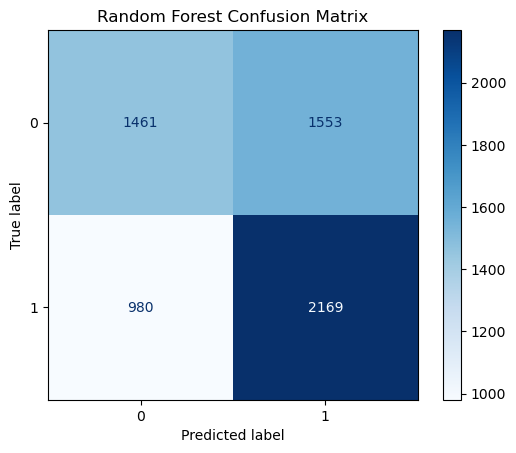

              precision    recall  f1-score   support

           0       0.60      0.48      0.54      3014
           1       0.58      0.69      0.63      3149

    accuracy                           0.59      6163
   macro avg       0.59      0.59      0.58      6163
weighted avg       0.59      0.59      0.58      6163



,Feature,Importance
9,days_with_impressions,0.128800
5,log_impressions_90d,0.115292
14,avg_position,0.104365
11,content_age_days,0.096891
4,char_count,0.051989
3,word_count,0.051110
16,scroll_rate,0.041741
13,ctr,0.038958
10,days_with_sessions,0.034103
6,log_clicks_90d,0.031584


In [114]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    rf_pred
))

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

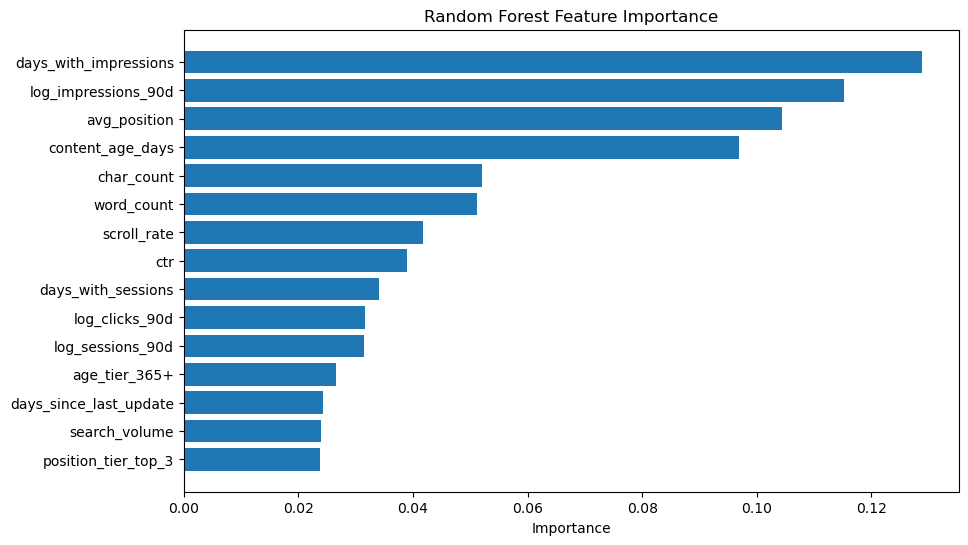

In [115]:
top = importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top["Feature"],
    top["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")

plt.show()

## 4. Errors and interpretation

The Random Forest achieved 0.59 accuracy on the client-held-out test set. For the declining class, it achieved 0.58 precision, 0.69 recall, and 0.63 F1-score.

The higher recall than precision means the model identified a relatively large share of declining pages, but some pages it flagged as declining were not actually labeled as declining. For a content-refresh workflow, this trade-off can be useful because missing a potentially declining page may be more costly than sending an extra page for human review.

The model's most important features were `days_with_impressions`, `log_impressions_90d`, `avg_position`, and `content_age_days`. These features describe historical visibility, search position, and content age, which are directionally consistent with the content-refresh problem.

The feature importance results describe which variables the Random Forest relied on most within this model. They should not be interpreted as causal effects. The Week-6 leakage audit also found no identified direct target leakage, while noting that the exact timing of some historical feature windows could not be independently verified.

Overall, the model provides useful decision-support evidence for prioritizing potentially declining pages, but the observed performance indicates that prediction remains imperfect and should be combined with human review.

In [86]:
comparison = pd.DataFrame(...)
comparison

ValueError: DataFrame constructor not properly called!

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.